In [1]:
import sys
sys.path.insert(0, '..')

import numpy as np
from matplotlib import pyplot as plt
from tqdm import tqdm
import jax.numpy as jnp
import jax
from scipy.special import erfc, erfcinv
from functools import partial, wraps

from lib import neurons, input_gen, driver, utils

In [11]:
ns=200
nd=300
n = 10
rng = jax.random.PRNGKey(12345)

beta=13.48 # non-int params1
b = 2.0
bk =  5.5

# beta=13.4492 # int params1
# b = 2.0
# bk =  5.5

hyper = neurons.HyperConfig1(nd=nd, ns=ns, n=n, b=b, bk=bk, beta=beta)
hyperD = neurons.HyperDynConfig1(b=b, bk=bk, beta=beta)
neuron = neurons.Neuron_Decay_NonInt(hyperparameters=hyper)
# neuron = neurons.Neuron_Decay_Int(hyperparameters=hyper)

rng, subkey = jax.random.split(rng)
# xs_gen = input_gen.Normal(nd, ns)
# xs_gen = input_gen.Normal_Corr_across_Dendrites(nd, ns, coeff=8, key=subkey)
xs_gen = input_gen.Normal_Corr_across_Dendrites(nd, ns, coeff=1, key=subkey)

rng, subkey = jax.random.split(rng)
my_driver = driver.Driver1_WeightCorr_record(neuron, xs_gen, subkey, hyperD, initial_state=None, resample_every=1000, n_tested_patterns=1000)

In [12]:
my_driver.run(
            n_init_steps=10000,
            n_steps_phase2=20000,
            n_steps_phase3=10000,
            test_every_phase3=50,
            bs=jnp.array([b])
        ) 

In [13]:
my_driver.steady_record[:, 0]

array([0.04036937, 0.04367416, 0.04143089, 0.04050118, 0.03785663,
       0.03925467, 0.04032458, 0.04039741, 0.04084972, 0.04342726,
       0.04504362, 0.04498853, 0.04549579, 0.04454768, 0.04688209,
       0.05054469, 0.0487385 , 0.04594184, 0.04533941, 0.04313589,
       0.04089987, 0.03996371, 0.04056543, 0.04069708, 0.03805076,
       0.03774403, 0.03526277, 0.03474147, 0.03199866, 0.03246176,
       0.02995912, 0.0308128 , 0.02880939, 0.02818808, 0.0310821 ,
       0.02962764, 0.0322055 , 0.03138107, 0.03413332, 0.03616163,
       0.03886845, 0.03808823, 0.03808419, 0.04051555, 0.03973164,
       0.03987851, 0.04081594, 0.03842811, 0.04015014, 0.04342765,
       0.04198721, 0.04248194, 0.04397426, 0.04373727, 0.04595108,
       0.04474232, 0.04260578, 0.04213267, 0.04201484, 0.04335233,
       0.03847367, 0.03881794, 0.03710724, 0.03417375, 0.03132876,
       0.03374937, 0.03822941, 0.04237543, 0.04217764, 0.04217551,
       0.04110987, 0.03691437, 0.03427028, 0.03335148, 0.03099

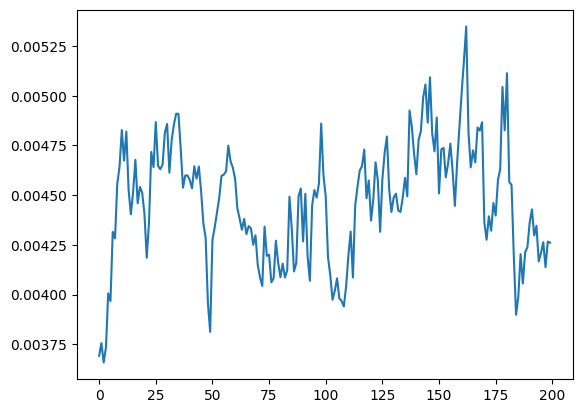

In [10]:
plt.plot(my_driver.steady_record[:, 0])

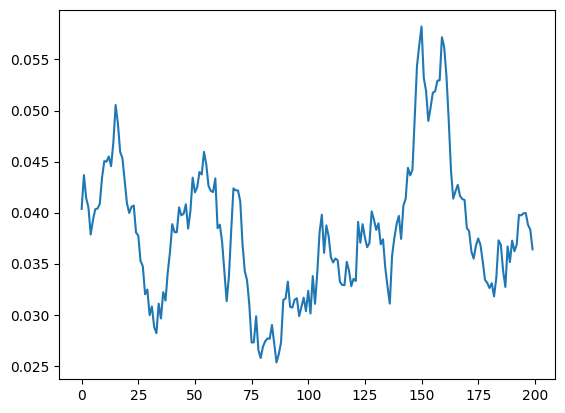

In [14]:
plt.plot(my_driver.steady_record[:, 0])